In [ ]:
!pip install psycopg2-binary pandas scikit-learn xgboost
!pip install category_encoders
!pip install catboost
import psycopg2
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 31.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.9/107.9 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.6 MB/s eta 0:00:00


Connecter la base de donnée sur supabase
(nous choisissons uniquenemt les colonnes bénefique pour l'étude )

In [ ]:
db_url = 'postgresql://postgres.######.supabase.com:5432/postgres'

query = """

SELECT
    rv.id AS rdv_id,
    rv.prospect_id,
    rv.agent,
    rv.type_fiche,
    rv.date_appel,
    rv.date_rdv,
    rv.heure_rdv,
    rv.status,
    p.revenu,
    p.credits_en_cours,
    p.situation_professionnelle_mr,
    p.situation_professionnelle_mme,
    p.enfants_a_charge,
    l.mode_chauffage,
    l.facture_annuelle,
    l.superficie_habitable,

    --  CHANGEMENT: created_at → date_rdv
    (
        SELECT COUNT(*)
        FROM rendez_vous rva
        WHERE rva.agent = rv.agent
          AND rva.date_rdv < rv.date_rdv  -- ← date_rdv au lieu de created_at
          AND rva.status IN ('Annulé', 'Confirmé')
    ) AS nb_rdv_prec_agent,

    --  CHANGEMENT: created_at → date_rdv
    (
        SELECT COUNT(*)
        FROM rendez_vous rva2
        WHERE rva2.agent = rv.agent
          AND rva2.date_rdv < rv.date_rdv  -- ← date_rdv au lieu de created_at
          AND rva2.status = 'Annulé'
    ) AS nb_annulations_prec_agent,

    --  CHANGEMENT: created_at → date_rdv
    CASE
        WHEN (
            SELECT COUNT(*)
            FROM rendez_vous rva3
            WHERE rva3.agent = rv.agent
              AND rva3.date_rdv < rv.date_rdv  -- ← date_rdv au lieu de created_at
              AND rva3.status IN ('Annulé', 'Confirmé')
        ) > 0
        THEN
            (
                SELECT COUNT(*)::FLOAT
                FROM rendez_vous rva4
                WHERE rva4.agent = rv.agent
                  AND rva4.date_rdv < rv.date_rdv  -- ← date_rdv au lieu de created_at
                  AND rva4.status = 'Annulé'
            )
            /
            (
                SELECT COUNT(*)::FLOAT
                FROM rendez_vous rva5
                WHERE rva5.agent = rv.agent
                  AND rva5.date_rdv < rv.date_rdv  -- ← date_rdv au lieu de created_at
                  AND rva5.status IN ('Annulé', 'Confirmé')
            )
        ELSE NULL
    END AS taux_annulation_prec_agent

FROM rendez_vous rv
LEFT JOIN prospects p ON p.id = rv.prospect_id
LEFT JOIN logements l ON l.id = rv.logement_id

WHERE rv.status IN ('Annulé', 'Confirmé');
"""


conn = psycopg2.connect(db_url)
df = pd.read_sql_query(query, conn)
conn.close()


/tmp/ipykernel_888/3937383558.py:78: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(query, conn)


Dimension du Dataset


In [ ]:
print(f"Lignes : {df.shape[0]}")
print(f"Colonnes : {df.shape[1]}")

Lignes : 4244
Colonnes : 19


In [ ]:
df.tail(30)

,rdv_id,prospect_id,agent,type_fiche,date_appel,date_rdv,heure_rdv,status,revenu,credits_en_cours,situation_professionnelle_mr,situation_professionnelle_mme,enfants_a_charge,mode_chauffage,facture_annuelle,superficie_habitable,nb_rdv_prec_agent,nb_annulations_prec_agent,taux_annulation_prec_agent
4214,e24c4740-0535-4f3b-b3a4-325d10bf7f8a,f38c9480-7228-415c-bbb1-d0833d1e629c,AGBOSSOU KOSSI ELOM,Fiche,NaT,2025-11-12,18:30:00,Confirmé,NaN,1600,indus,indus,600.0,Autre,NaN,NaN,4,1,0.250000
4215,e3dc80fb-2e0f-4c03-ad8d-78ba67dbe690,90f07ff7-b382-40d0-9dbc-3e98c9efc414,TIESSE,RDV,2026-07-16 17:02:20,2026-07-23,15:30:00,Confirmé,1500.0,00,retraite,active,3.0,Gaz,2500.0,120.0,69,34,0.492754
4216,1bc90805-7014-43cb-860c-a0ae2e077106,d7e57484-f4b5-431a-a03e-8581c403164e,KHAYATE KHADIJA,RDV,2026-03-02 12:38:34,2026-03-04,None,Confirmé,1200.0,0,----,fonctionnaire,1.0,Fioul,2020.0,80.0,125,82,0.656000
4217,c1bd38e2-caf8-4a82-a14a-afddb3fa850e,487edd9a-0632-4f97-adf0-24cffc6bef83,ALIOU SAMAKE,RDV,2026-02-02 12:55:54,None,None,Annulé,1200.0,,actif,active,1.0,Electricite,1000.0,250.0,0,0,NaN
4218,3eda212c-00e2-4f2a-b757-19737292d969,aee7e4b3-61e0-4bce-9c28-5a709f170187,CHRISTIAN MALIK,RDV,2025-10-16 16:52:01,2025-10-21,None,Annulé,2900.0,1300,actif,active,4.0,Bois,1000.0,NaN,19,11,0.578947
4219,9d712cba-0a27-468b-b85d-893c8f9b093b,761ea9ce-715f-4bd2-ad27-401f4919d39c,YASSINE BOUCHEBCHOUB,Fiche,NaT,2026-07-07,None,Confirmé,27003000.0,1500,actif,-,None,Pompe_a_chaleur,1800.0,100.0,114,55,0.482456
4220,b7257ce8-cd94-4dac-ae1f-afe396ce5871,4be72ac5-0d4b-4215-b5e9-e7cba9759ec1,NELLE YVAN,RDV,2026-03-23 13:21:19,2026-03-24,None,Confirmé,1850.0,700,non actif,active,1.0,Electricite,1200.0,NaN,278,153,0.550360
4221,11c68e8c-8400-43af-aa22-87bd6fa332c9,40f17285-0058-4778-9fe8-f6c145e3a98d,BABA SOUFIANE,RDV,2026-03-12 13:41:56,2026-03-17,None,Confirmé,1000.0,0,retraite,retraite,0.0,Gaz,1000.0,130.0,155,108,0.696774
4222,07550a55-3114-438d-bc58-29c1c6a5be77,0df15bd8-e17b-4475-9174-b230679fe628,BOUMARGOUD AZIZ,RDV,2025-10-27 10:24:43,2025-10-29,None,Annulé,5200.0,4000,actif,création d entreprise,1.0,Electricite,4800.0,120.0,84,51,0.607143
4223,1b30a066-6938-4534-a926-b397e6b51df5,4f8e75b1-b91c-44f1-8f30-1329e5722b13,CHRISTIAN MALIK,RDV,2025-10-21 10:33:56,2025-10-24,None,Annulé,2300.0,1000,actif,active,1.0,Pompe_a_chaleur,4000.0,70.0,26,14,0.538462


In [ ]:
print(df.columns.tolist())


['rdv_id', 'prospect_id', 'agent', 'type_fiche', 'date_appel', 'date_rdv', 'heure_rdv', 'status', 'revenu', 'credits_en_cours', 'situation_professionnelle_mr', 'situation_professionnelle_mme', 'enfants_a_charge', 'mode_chauffage', 'facture_annuelle', 'superficie_habitable', 'nb_rdv_prec_agent', 'nb_annulations_prec_agent', 'taux_annulation_prec_agent']


In [ ]:
print(df["status"].value_counts())
print(df["status"].value_counts(normalize=True) * 100)

status
Annulé      2410
Confirmé    1834
Name: count, dtype: int64
status
Annulé      56.786051
Confirmé    43.213949
Name: proportion, dtype: float64


In [ ]:
df['revenu'] = pd.to_numeric(df['revenu'], errors='coerce')
df['credits_en_cours'] = pd.to_numeric(df['credits_en_cours'], errors='coerce')

In [ ]:
df["conso_m2"] = (
    df["facture_annuelle"] /
    df["superficie_habitable"].replace(0, np.nan) )

df["conso_m2"] = df["conso_m2"].fillna(0)

In [ ]:
df['date_appel'] = pd.to_datetime(df['date_appel'], errors='coerce')
df['date_rdv'] = pd.to_datetime(df['date_rdv'], errors='coerce')
df['delai_appel_rdv_jours'] = (
    df['date_rdv'].dt.normalize() -
    df['date_appel'].dt.normalize()
).dt.days





In [ ]:
df['situation_professionnelle_mr'] = df['situation_professionnelle_mr'].fillna('inconnu')
df['situation_professionnelle_mme'] = df['situation_professionnelle_mme'].fillna('inconnu')

In [ ]:
def normalize_category(value):
    """Normalise les catégories inconsistantes"""
    if pd.isna(value):
        return 'inconnu'

    value = str(value).strip().lower()


    if 'actif' in value or 'active' in value:
        return 'actif'
    if 'retraite' in value or 'retraité' in value or 'retraitée' in value:
        return 'retraite'
    if 'sans' in value or 'emploi' in value:
        return 'sans_emploi'

    # Tirets seuls
    if value in ['---', '--', '-', '----', '']:
        return 'inconnu'

    return 'autre'

categorical_cols = [
    'situation_professionnelle_mr',
    'situation_professionnelle_mme',
]

for col in categorical_cols:
    if col in df.columns:
        df[col] = df[col].apply(normalize_category)

In [ ]:
df['revenu'] = pd.to_numeric(df['revenu'], errors='coerce')
Q1_revenu = df['revenu'].quantile(0.25)
Q3_revenu = df['revenu'].quantile(0.75)
IQR_revenu = Q3_revenu - Q1_revenu
lower_bound = Q1_revenu - 3 * IQR_revenu
upper_bound = Q3_revenu + 3 * IQR_revenu
df.loc[(df['revenu'] < lower_bound) | (df['revenu'] > upper_bound), 'revenu'] = np.nan
print(f"      Outliers supprimés, médiane: {df['revenu'].median():,.0f}")

# Credits en cours - Gérer le format "00"
print("   Credits en cours...")
if 'credits_en_cours' in df.columns:
    df['credits_en_cours'] = df['credits_en_cours'].astype(str).str.strip()
    df['credits_en_cours'] = df['credits_en_cours'].replace({'00': '0', '': np.nan})
    df['credits_en_cours'] = pd.to_numeric(df['credits_en_cours'], errors='coerce')
    print(f"      OK, médiane: {df['credits_en_cours'].median():,.0f}")

# Facture annuelle
print("   Facture annuelle...")
df['facture_annuelle'] = pd.to_numeric(df['facture_annuelle'], errors='coerce')
df.loc[df['facture_annuelle'] <= 0, 'facture_annuelle'] = np.nan
print(f"      OK, médiane: {df['facture_annuelle'].median():,.0f}")

# Superficie
print("   Superficie habitable...")
df['superficie_habitable'] = pd.to_numeric(df['superficie_habitable'], errors='coerce')
df.loc[df['superficie_habitable'] <= 0, 'superficie_habitable'] = np.nan

      Outliers supprimés, médiane: 2,000
   Credits en cours...
      OK, médiane: 700
   Facture annuelle...
      OK, médiane: 1,500
   Superficie habitable...


In [ ]:
df.tail(20)

,rdv_id,prospect_id,agent,type_fiche,date_appel,date_rdv,heure_rdv,status,revenu,credits_en_cours,...,situation_professionnelle_mme,enfants_a_charge,mode_chauffage,facture_annuelle,superficie_habitable,nb_rdv_prec_agent,nb_annulations_prec_agent,taux_annulation_prec_agent,conso_m2,delai_appel_rdv_jours
4224,22914290-228d-4306-99e0-3b2e2cfa9f12,1fa70cff-1e90-4221-b318-d85ee08c71e2,BABA SOUFIANE,RDV,2026-03-17 17:11:49,2026-03-19,None,Annulé,1700.0,700.0,...,actif,0.0,Gaz,NaN,NaN,159,110,0.691824,0.000000,2.0
4225,5c6d490a-35c7-49c5-89a4-8fbb43bba553,e28ac9c8-292f-408c-ae96-6b71e935e4b6,NELLE YVAN,RDV,2025-10-13 11:35:23,2025-10-21,None,Confirmé,4000.0,2500.0,...,actif,2.0,Gaz,2400.0,175.0,51,19,0.372549,13.714286,8.0
4226,b64a4a72-d093-470d-b8dd-643f60445f30,a4771550-9ac9-4082-836e-3031b9aad461,LAILA BOUGARNE,RDV,2026-02-18 14:49:32,2026-02-20,None,Annulé,1000.0,0.0,...,actif,0.0,Autre,3000.0,165.0,128,73,0.570312,18.181818,2.0
4227,a1e1170e-1c7f-4096-a0a2-79ee5601630b,643cd5e4-6ddf-4505-8a5c-8e1029784241,BOUMARGOUD AZIZ,RDV,2026-01-16 15:04:27,2026-01-20,None,Annulé,2500.0,1200.0,...,actif,1.0,Mixte,1440.0,NaN,197,117,0.593909,0.000000,4.0
4228,9f4d9b05-32ec-4b54-8f30-8968b444018a,42ad925e-5330-4af4-a5b0-868426695172,BABA SOUFIANE,RDV,2026-03-25 15:32:34,2026-03-26,None,Annulé,1200.0,0.0,...,autre,0.0,Fioul,2412.0,NaN,167,115,0.688623,0.000000,1.0
4229,bf4f7391-29d9-44fb-92e3-5e7b2ac5cef2,90094ca7-ef74-4e9e-b9ad-b3770be3840c,CLAUDE MABOUNGA,RDV,2025-09-29 09:39:01,2025-09-30,None,Confirmé,2000.0,1700.0,...,actif,2.0,Electricite,1600.0,120.0,11,8,0.727273,13.333333,1.0
4230,6209fdbb-2529-4f2f-a4c4-463b4d40d240,810b20e4-3cf8-4c8e-96a7-a11eb9ea9276,KHAYATE KHADIJA,RDV,2025-12-12 13:06:42,2025-12-16,None,Confirmé,1700.0,680.0,...,inconnu,0.0,Bois,1056.0,98.0,69,46,0.666667,10.775510,4.0
4231,c1456180-e54d-42e1-8860-e74a1a09f030,28f64f89-2d23-466f-abb2-3b823e1beb62,CLAUDE MABOUNGA,RDV,2025-12-04 13:20:33,2025-12-08,None,Confirmé,1000.0,0.0,...,retraite,0.0,Electricite,1000.0,NaN,85,50,0.588235,0.000000,4.0
4232,5e02e2b3-46e2-4e7e-8ad6-14932c402114,321ef362-8180-47da-bb00-e6373ccae381,BABA SOUFIANE,RDV,2026-03-12 10:14:53,2026-03-18,None,Annulé,NaN,1000.0,...,actif,2.0,Mixte,1200.0,160.0,158,109,0.689873,7.500000,6.0
4233,56e39fe1-9294-4e3a-9a43-facadc149960,c55a72b1-21da-4edc-b1c3-d068a5a66151,BOUGATAIA FATIMA AZZAHRA,RDV,2026-02-20 15:28:31,2026-02-24,None,Annulé,2250.0,800.0,...,autre,3.0,Autre,1500.0,NaN,93,50,0.537634,0.000000,4.0


# ML amélioré — Prédiction des RDV Confirmé / Annulé

Cette version reprend le chargement et le nettoyage du notebook source, puis remplace la partie ML par un pipeline plus robuste.

**Principes :**
- uniquement `Annulé` vs `Confirmé`;
- séparation train/test avant tout encodage supervisé;
- suppression de `agent` encodé par target encoding pour éviter la redondance avec l'historique agent;
- feature engineering disponible au moment de la prédiction;
- historique agent calculé de façon chronologique pour éviter la fuite;
- comparaison XGBoost / CatBoost;
- validation croisée;
- optimisation du seuil sur le train uniquement;
- métriques : Accuracy, Balanced Accuracy, Precision, Recall, F1, ROC-AUC, MCC, Log Loss;
- analyse SHAP si la librairie est disponible;
- sauvegarde du meilleur modèle + preprocessing + seuil.


In [ ]:
# ============================================================
# 1. Imports
# ============================================================
import warnings
warnings.filterwarnings("ignore")

import os
import json
import joblib
import numpy as np
import pandas as pd

from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, matthews_corrcoef,
    log_loss, classification_report, confusion_matrix
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier

from xgboost import XGBClassifier

try:
    from catboost import CatBoostClassifier
    CATBOOST_AVAILABLE = True
except Exception:
    CATBOOST_AVAILABLE = False

RANDOM_STATE = 42
TARGET = "target_status"

print("CatBoost disponible :", CATBOOST_AVAILABLE)


CatBoost disponible : True


In [ ]:
# ============================================================
# 2. Préparer la cible
# ============================================================
# On conserve la colonne status dans df pour le contrôle qualité,
# mais elle ne doit jamais entrer comme feature.

df = df.copy()

df["status"] = (
    df["status"]
    .astype(str)
    .str.strip()
    .str.replace("é", "é", regex=False)
)

# Uniquement les deux classes réellement prédites
df_ml = df[df["status"].isin(["Annulé", "Confirmé"])].copy()

df_ml[TARGET] = df_ml["status"].map({"Annulé": 0, "Confirmé": 1}).astype(int)

print("Taille ML :", len(df_ml))
print(df_ml["status"].value_counts(dropna=False))
print(df_ml[TARGET].value_counts(normalize=True).rename("proportion"))


Taille ML : 4244
status
Annulé      2410
Confirmé    1834
Name: count, dtype: int64
target_status
0    0.567861
1    0.432139
Name: proportion, dtype: float64


In [ ]:
# ============================================================
# 3. Nettoyage robuste des colonnes numériques
# ============================================================
numeric_candidates = [
    "revenu", "credits_en_cours", "enfants_a_charge",
    "facture_annuelle", "superficie_habitable",
    "superficie_toiture", "annee_construction",
    "nb_rdv_prec_agent", "nb_annulations_prec_agent",
    "taux_annulation_prec_agent", "conso_m2",
    "delai_appel_rdv_jours", "lead_time_days",
]

for col in numeric_candidates:
    if col in df_ml.columns:
        if df_ml[col].dtype == "object":
            # Nettoyage prudent des formats monétaires / espaces
            s = (
                df_ml[col].astype(str)
                .str.replace("\u202f", "", regex=False)
                .str.replace("\xa0", "", regex=False)
                .str.replace(" ", "", regex=False)
                .str.replace(",", ".", regex=False)
                .str.replace(r"[^0-9.\-]", "", regex=True)
            )
            df_ml[col] = pd.to_numeric(s, errors="coerce")
        else:
            df_ml[col] = pd.to_numeric(df_ml[col], errors="coerce")

# Valeurs aberrantes extrêmes : on ne supprime pas les lignes,
# on les remplace par NaN et l'imputation sera faite dans le pipeline.
bounds = {
    "revenu": (0, 1_000_000),
    "credits_en_cours": (0, 100),
    "enfants_a_charge": (0, 30),
    "facture_annuelle": (0, 1_000_000),
    "superficie_habitable": (5, 2_000),
    "superficie_toiture": (5, 5_000),
    "annee_construction": (1800, 2035),
    "conso_m2": (0, 10_000),
    "lead_time_days": (-1, 365),
    "delai_appel_rdv_jours": (-1, 365),
}

for col, (lo, hi) in bounds.items():
    if col in df_ml.columns:
        mask = (df_ml[col] < lo) | (df_ml[col] > hi)
        df_ml.loc[mask, col] = np.nan

print("Nettoyage numérique terminé.")


Nettoyage numérique terminé.


In [ ]:
# ============================================================
# 4. Feature engineering
# ============================================================
def add_features(data):
    d = data.copy()

    # Dates
    for c in ["date_appel", "date_rdv"]:
        if c in d.columns:
            d[c] = pd.to_datetime(d[c], errors="coerce")

    # Heure du RDV
    if "heure_rdv" in d.columns and "heure_rdv_int" not in d.columns:
        h = d["heure_rdv"].astype(str).str.extract(r"(\d{1,2})")[0]
        d["heure_rdv_int"] = pd.to_numeric(h, errors="coerce")

    # Délai appel -> RDV
    if "date_appel" in d.columns and "date_rdv" in d.columns:
        delta = (d["date_rdv"] - d["date_appel"]).dt.total_seconds() / 86400
        d["lead_time_days"] = delta.clip(-1, 365)

    # Variables calendaires
    if "date_rdv" in d.columns:
        d["jour_semaine_rdv"] = d["date_rdv"].dt.dayofweek
        d["mois_rdv"] = d["date_rdv"].dt.month
        d["semaine_annee_rdv"] = d["date_rdv"].dt.isocalendar().week.astype(float)
        d["est_weekend_rdv"] = (d["jour_semaine_rdv"] >= 5).astype(int)
        d["est_fin_mois"] = d["date_rdv"].dt.is_month_end.astype(int)

    # Ratio facture / revenu : signal économique potentiellement utile.
    if "facture_annuelle" in d.columns and "revenu" in d.columns:
        d["ratio_facture_revenu"] = (
            d["facture_annuelle"] / d["revenu"].replace(0, np.nan)
        )
        d["ratio_facture_revenu"] = d["ratio_facture_revenu"].clip(0, 10)

    # Consommation par m² si disponible
    if "conso_m2" in d.columns:
        d["conso_m2_missing"] = d["conso_m2"].isna().astype(int)

    # Missingness informative
    missing_cols = [
        "revenu", "credits_en_cours", "facture_annuelle",
        "superficie_habitable", "mode_chauffage",
        "situation_professionnelle_mr",
        "situation_professionnelle_mme"
    ]
    existing = [c for c in missing_cols if c in d.columns]
    if existing:
        d["nb_valeurs_manquantes"] = d[existing].isna().sum(axis=1)

    return d

df_ml = add_features(df_ml)

print("Features ajoutées :")
for c in [
    "lead_time_days", "jour_semaine_rdv", "mois_rdv",
    "semaine_annee_rdv", "est_weekend_rdv", "est_fin_mois",
    "ratio_facture_revenu", "conso_m2_missing", "nb_valeurs_manquantes"
]:
    if c in df_ml.columns:
        print(" -", c)


Features ajoutées :
 - lead_time_days
 - jour_semaine_rdv
 - mois_rdv
 - semaine_annee_rdv
 - est_weekend_rdv
 - est_fin_mois
 - ratio_facture_revenu
 - conso_m2_missing
 - nb_valeurs_manquantes


In [ ]:
# ============================================================
# 5. Historique agent sans fuite de données
# ============================================================
# Très important :
# pour chaque RDV, l'historique doit utiliser uniquement les RDV
# antérieurs à celui-ci. On ne calcule donc PAS la moyenne sur tout
# le dataset avant le split.

def add_agent_history(data):
    d = data.copy()

    if "agent" not in d.columns:
        return d

    if "date_rdv" in d.columns:
        sort_col = "date_rdv"
    elif "date_appel" in d.columns:
        sort_col = "date_appel"
    else:
        # fallback déterministe
        sort_col = None

    if sort_col:
        d = d.sort_values([sort_col]).copy()

    # On utilise la cible uniquement pour construire l'historique passé.
    # Expanding/cumsum est effectué ligne par ligne.
    if "target_status" in d.columns:
        d["_agent_total_before"] = d.groupby("agent").cumcount()
        d["_agent_cancel_before"] = (
            d.groupby("agent")[TARGET]
             .cumsum()
             .shift(1)
        )
        # Le shift global n'est pas correct lorsque les groupes changent :
        # on recalcule explicitement le cumul précédent par groupe.
        d["_agent_cancel_before"] = (
            d.groupby("agent")[TARGET]
             .transform(lambda s: s.shift(1).fillna(0).cumsum())
        )

        d["nb_rdv_prec_agent"] = d["_agent_total_before"].astype(float)
        d["nb_annulations_prec_agent"] = d["_agent_cancel_before"].astype(float)

        # Lissage bayésien léger pour éviter des taux 0/1 sur les nouveaux agents.
        global_rate = d[TARGET].mean()
        alpha = 10.0
        d["taux_annulation_prec_agent"] = (
            (d["nb_annulations_prec_agent"] + alpha * global_rate) /
            (d["nb_rdv_prec_agent"] + alpha)
        )

        d.drop(columns=["_agent_total_before", "_agent_cancel_before"], inplace=True)

    return d

df_ml = add_agent_history(df_ml)

print(df_ml[[
    c for c in ["agent", "nb_rdv_prec_agent",
                "nb_annulations_prec_agent", "taux_annulation_prec_agent"]
    if c in df_ml.columns
]].head())


               agent  nb_rdv_prec_agent  nb_annulations_prec_agent  \
280                                 0.0                        0.0   
1172  FRANCK HERMANN                0.0                        0.0   
1889  FRANCK HERMANN                1.0                        0.0   
1886  FRANCK HERMANN                2.0                        0.0   
2542  FRANCK HERMANN                3.0                        0.0   

      taux_annulation_prec_agent  
280                     0.432139  
1172                    0.432139  
1889                    0.392854  
1886                    0.360116  
2542                    0.332415  


In [ ]:
# ============================================================
# 6. Split chronologique si possible
# ============================================================
# Pour un problème opérationnel, une séparation temporelle est plus
# réaliste qu'un split aléatoire : on entraîne sur le passé et teste
# sur le futur.

if "date_rdv" in df_ml.columns and df_ml["date_rdv"].notna().sum() > 0:
    df_ml = df_ml.sort_values("date_rdv").reset_index(drop=True)

    split_idx = int(len(df_ml) * 0.80)
    train_df = df_ml.iloc[:split_idx].copy()
    test_df = df_ml.iloc[split_idx:].copy()
else:
    train_df, test_df = train_test_split(
        df_ml,
        test_size=0.20,
        stratify=df_ml[TARGET],
        random_state=RANDOM_STATE
    )

print("Train :", train_df.shape)
print("Test  :", test_df.shape)
print("\nTrain target:")
print(train_df[TARGET].value_counts(normalize=True))
print("\nTest target:")
print(test_df[TARGET].value_counts(normalize=True))


Train : (3395, 32)
Test  : (849, 32)

Train target:
target_status
0    0.568778
1    0.431222
Name: proportion, dtype: float64

Test target:
target_status
0    0.564193
1    0.435807
Name: proportion, dtype: float64


In [ ]:
# ============================================================
# 7. Construction des features
# ============================================================
DROP_COLS = [
    TARGET,
    "status",              # cible brute
    "commentaire",         # information post-RDV -> fuite potentielle
    "motif_annulation",    # connu après annulation -> fuite
    "rdv_id",
    "prospect_id",
    "date_appel",
    "date_rdv",
    "heure_rdv",
]

# Agent volontairement supprimé :
# le SHAP précédent montrait une forte redondance avec
# taux_annulation_prec_agent.
#
# On garde l'historique agent, qui est disponible au moment
# de la prédiction et plus explicable.

if "agent" in train_df.columns:
    DROP_COLS.append("agent")

feature_cols = [c for c in train_df.columns if c not in DROP_COLS]

X_train = train_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()
y_train = train_df[TARGET].copy()
y_test = test_df[TARGET].copy()

cat_cols = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
num_cols = [c for c in X_train.columns if c not in cat_cols]

print("Nombre features :", len(feature_cols))
print("Catégorielles :", cat_cols)
print("Numériques :", num_cols)


Nombre features : 24
Catégorielles : ['type_fiche', 'situation_professionnelle_mr', 'situation_professionnelle_mme', 'mode_chauffage']
Numériques : ['revenu', 'credits_en_cours', 'enfants_a_charge', 'facture_annuelle', 'superficie_habitable', 'nb_rdv_prec_agent', 'nb_annulations_prec_agent', 'taux_annulation_prec_agent', 'conso_m2', 'delai_appel_rdv_jours', 'heure_rdv_int', 'lead_time_days', 'jour_semaine_rdv', 'mois_rdv', 'semaine_annee_rdv', 'est_weekend_rdv', 'est_fin_mois', 'ratio_facture_revenu', 'conso_m2_missing', 'nb_valeurs_manquantes']


In [ ]:
# ============================================================
# 8. Préprocessing
# ============================================================
# OneHotEncoder est utilisé ici plutôt que TargetEncoder :
# il évite l'encodage supervisé manuel et simplifie le pipeline de
# production.

try:
    ohe = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    ohe = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median", add_indicator=True))
            ]),
            num_cols
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", ohe)
            ]),
            cat_cols
        ),
    ],
    remainder="drop"
)

X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)

print("Shape après preprocessing :", X_train_p.shape)


Shape après preprocessing : (3395, 65)


In [ ]:
# ============================================================
# 9. Baselines
# ============================================================
def evaluate_model(name, y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)

    return {
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, pred),
        "Balanced_Accuracy": balanced_accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, proba),
        "MCC": matthews_corrcoef(y_true, pred),
        "Log_Loss": log_loss(y_true, np.clip(proba, 1e-7, 1-1e-7)),
    }

majority_class = int(y_train.mean() >= 0.5)
baseline_proba = np.full(len(y_test), y_train.mean())

baseline = evaluate_model(
    "Baseline probabiliste",
    y_test,
    baseline_proba,
    threshold=0.5
)

print(pd.DataFrame([baseline]).round(4))


                   Model  Threshold  Accuracy  Balanced_Accuracy  Precision  \
0  Baseline probabiliste        0.5    0.5642                0.5        0.0   

   Recall   F1  ROC_AUC  MCC  Log_Loss  
0     0.0  0.0      0.5  0.0    0.6849  


In [ ]:
# ============================================================
# 10. XGBoost — recherche raisonnable d'hyperparamètres
# ============================================================
pos = (y_train == 1).sum()
neg = (y_train == 0).sum()
scale_pos_weight = neg / max(pos, 1)

xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    scale_pos_weight=scale_pos_weight,
)

param_dist = {
    "n_estimators": [150, 250, 400, 600],
    "max_depth": [2, 3, 4, 5],
    "learning_rate": [0.02, 0.04, 0.06, 0.1],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
    "min_child_weight": [1, 3, 5, 8],
    "gamma": [0, 0.1, 0.3],
    "reg_alpha": [0, 0.05, 0.2],
    "reg_lambda": [1, 2, 5, 10],
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_dist,
    n_iter=35,
    scoring="roc_auc",
    cv=cv,
    verbose=1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True
)

search.fit(X_train_p, y_train)

best_xgb = search.best_estimator_

print("Best CV ROC-AUC :", round(search.best_score_, 4))
print("Best params :")
print(search.best_params_)


Fitting 5 folds for each of 35 candidates, totalling 175 fits
Best CV ROC-AUC : 0.5876
Best params :
{'subsample': 0.7, 'reg_lambda': 2, 'reg_alpha': 0.2, 'n_estimators': 150, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 1.0}


In [ ]:
# ============================================================
# 11. CatBoost si disponible
# ============================================================
best_cat = None
cat_proba_test = None

if CATBOOST_AVAILABLE:
    cat = CatBoostClassifier(
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=RANDOM_STATE,
        verbose=False,
        thread_count=-1,
        auto_class_weights="Balanced"
    )

    cat_params = {
        "iterations": [200, 400, 600, 800],
        "depth": [3, 4, 5, 6, 7],
        "learning_rate": [0.02, 0.04, 0.06, 0.1],
        "l2_leaf_reg": [1, 3, 5, 8, 12],
        "random_strength": [0.2, 0.5, 1.0, 2.0],
    }

    cat_search = RandomizedSearchCV(
        cat,
        cat_params,
        n_iter=25,
        scoring="roc_auc",
        cv=cv,
        verbose=1,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True
    )

    cat_search.fit(X_train_p, y_train)
    best_cat = cat_search.best_estimator_

    print("Best CatBoost CV ROC-AUC :", round(cat_search.best_score_, 4))
    print("Best CatBoost params :")
    print(cat_search.best_params_)
else:
    print("CatBoost non disponible — XGBoost sera utilisé.")


Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best CatBoost CV ROC-AUC : 0.6008
Best CatBoost params :
{'random_strength': 1.0, 'learning_rate': 0.04, 'l2_leaf_reg': 8, 'iterations': 200, 'depth': 4}


In [ ]:
# ============================================================
# 12. Prédictions probabilistes
# ============================================================
xgb_proba_test = best_xgb.predict_proba(X_test_p)[:, 1]

results = [
    evaluate_model("XGBoost", y_test, xgb_proba_test, threshold=0.5)
]

if best_cat is not None:
    cat_proba_test = best_cat.predict_proba(X_test_p)[:, 1]
    results.append(
        evaluate_model("CatBoost", y_test, cat_proba_test, threshold=0.5)
    )

results_df = pd.DataFrame(results).sort_values(
    "ROC_AUC", ascending=False
)

display(results_df.round(4))


,Model,Threshold,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,MCC,Log_Loss
1,CatBoost,0.5,0.5713,0.5930,0.5054,0.7622,0.6078,0.6291,0.1943,0.6797
0,XGBoost,0.5,0.5713,0.5841,0.5060,0.6838,0.5816,0.6071,0.1694,0.6910


In [ ]:
# ============================================================
# 13. Optimisation du seuil — UNIQUEMENT sur une validation interne
# ============================================================
# Ne pas choisir le seuil directement sur le test :
# sinon le test cesse d'être un vrai jeu d'évaluation.

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_p,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=RANDOM_STATE
)

threshold_model = XGBClassifier(**search.best_estimator_.get_params())
threshold_model.fit(X_tr, y_tr)

val_proba = threshold_model.predict_proba(X_val)[:, 1]

threshold_rows = []
for threshold in np.arange(0.25, 0.751, 0.01):
    pred = (val_proba >= threshold).astype(int)

    threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "accuracy": accuracy_score(y_val, pred),
        "balanced_accuracy": balanced_accuracy_score(y_val, pred),
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0),
        "mcc": matthews_corrcoef(y_val, pred),
    })

threshold_df = pd.DataFrame(threshold_rows)

# Critère principal : MCC, plus adapté qu'Accuracy seule en cas
# de déséquilibre. F1 sert de critère secondaire.
best_threshold_row = threshold_df.sort_values(
    ["mcc", "f1"],
    ascending=False
).iloc[0]

BEST_THRESHOLD = float(best_threshold_row["threshold"])

print("Seuil optimal validation :", BEST_THRESHOLD)
display(
    threshold_df.sort_values(["mcc", "f1"], ascending=False).head(10).round(4)
)


Seuil optimal validation : 0.59


,threshold,accuracy,balanced_accuracy,precision,recall,f1,mcc
34,0.59,0.6009,0.5671,0.5663,0.3208,0.4096,0.1548
33,0.58,0.5979,0.5670,0.5556,0.3413,0.4228,0.1504
26,0.51,0.5803,0.5745,0.5132,0.5324,0.5226,0.1484
31,0.56,0.5920,0.5688,0.5367,0.3993,0.4579,0.1460
35,0.60,0.5965,0.5596,0.5629,0.2901,0.3829,0.1419
28,0.53,0.5817,0.5692,0.5166,0.4778,0.4965,0.1400
25,0.50,0.5714,0.5692,0.5031,0.5529,0.5268,0.1373
32,0.57,0.5891,0.5625,0.5347,0.3686,0.4364,0.1355
36,0.61,0.5920,0.5516,0.5597,0.2560,0.3513,0.1283
27,0.52,0.5714,0.5634,0.5034,0.5051,0.5043,0.1268


In [ ]:
# ============================================================
# 14. Évaluation finale avec le seuil choisi sans regarder le test
# ============================================================
final_results = []

final_results.append(
    evaluate_model(
        "XGBoost optimisé",
        y_test,
        xgb_proba_test,
        threshold=BEST_THRESHOLD
    )
)

if cat_proba_test is not None:
    # On teste aussi CatBoost avec le même principe de seuil 0.5 ici.
    # Le meilleur modèle est choisi sur ROC-AUC + MCC/F1.
    final_results.append(
        evaluate_model(
            "CatBoost",
            y_test,
            cat_proba_test,
            threshold=0.5
        )
    )

final_df = pd.DataFrame(final_results).sort_values(
    ["MCC", "ROC_AUC", "F1"],
    ascending=False
)

display(final_df.round(4))

best_name = final_df.iloc[0]["Model"]
print("\nMeilleur modèle selon MCC puis ROC-AUC :", best_name)


,Model,Threshold,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,MCC,Log_Loss
1,CatBoost,0.50,0.5713,0.5930,0.5054,0.7622,0.6078,0.6291,0.1943,0.6797
0,XGBoost optimisé,0.59,0.5901,0.5722,0.5369,0.4324,0.4790,0.6071,0.1500,0.6910



Meilleur modèle selon MCC puis ROC-AUC : CatBoost


In [ ]:
# ============================================================
# 15. Rapport détaillé + matrice de confusion
# ============================================================
if best_name == "XGBoost optimisé":
    final_proba = xgb_proba_test
    final_threshold = BEST_THRESHOLD
    final_model = best_xgb
else:
    final_proba = cat_proba_test
    final_threshold = 0.5
    final_model = best_cat

final_pred = (final_proba >= final_threshold).astype(int)

print("Classification report :")
print(
    classification_report(
        y_test,
        final_pred,
        target_names=["Annulé", "Confirmé"],
        digits=4,
        zero_division=0
    )
)

print("Confusion matrix :")
cm = confusion_matrix(y_test, final_pred)
print(cm)

print("\nTN =", cm[0,0], "| FP =", cm[0,1])
print("FN =", cm[1,0], "| TP =", cm[1,1])


Classification report :
              precision    recall  f1-score   support

      Annulé     0.6976    0.4238    0.5273       479
    Confirmé     0.5054    0.7622    0.6078       370

    accuracy                         0.5713       849
   macro avg     0.6015    0.5930    0.5675       849
weighted avg     0.6138    0.5713    0.5623       849

Confusion matrix :
[[203 276]
 [ 88 282]]

TN = 203 | FP = 276
FN = 88 | TP = 282


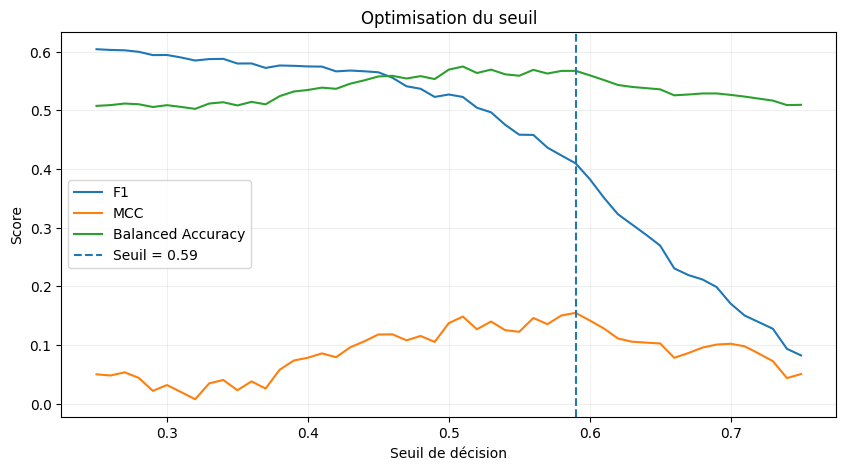

In [ ]:
# ============================================================
# 16. Courbe des métriques selon le seuil
# ============================================================
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(threshold_df["threshold"], threshold_df["f1"], label="F1")
plt.plot(threshold_df["threshold"], threshold_df["mcc"], label="MCC")
plt.plot(
    threshold_df["threshold"],
    threshold_df["balanced_accuracy"],
    label="Balanced Accuracy"
)
plt.axvline(BEST_THRESHOLD, linestyle="--", label=f"Seuil = {BEST_THRESHOLD:.2f}")
plt.xlabel("Seuil de décision")
plt.ylabel("Score")
plt.title("Optimisation du seuil")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


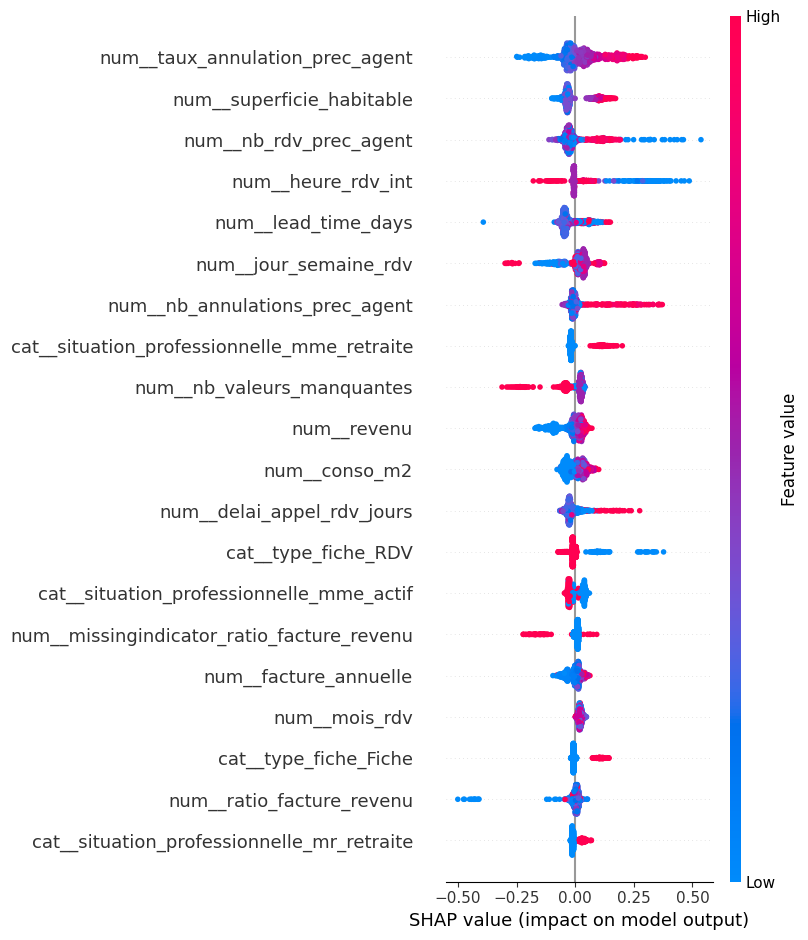

In [ ]:
# ============================================================
# 17. SHAP — interprétation du modèle
# ============================================================
try:
    import shap

    # SHAP sur un échantillon pour rester rapide
    n_shap = min(800, len(X_test_p))
    rng = np.random.default_rng(RANDOM_STATE)
    idx = rng.choice(len(X_test_p), size=n_shap, replace=False)

    X_shap = X_test_p[idx]

    explainer = shap.TreeExplainer(final_model)
    shap_values = explainer.shap_values(X_shap)

    feature_names = preprocessor.get_feature_names_out()

    shap.summary_plot(
        shap_values,
        X_shap,
        feature_names=feature_names,
        max_display=20
    )

except Exception as e:
    print("SHAP non exécuté :", repr(e))


In [ ]:
# ============================================================
# 18. Importance des variables
# ============================================================
try:
    feature_names = preprocessor.get_feature_names_out()
    importances = final_model.feature_importances_

    importance_df = (
        pd.DataFrame({
            "feature": feature_names,
            "importance": importances
        })
        .sort_values("importance", ascending=False)
        .head(25)
    )

    display(importance_df)

except Exception as e:
    print("Importance indisponible :", repr(e))


,feature,importance
7,num__taux_annulation_prec_agent,9.823229
5,num__nb_rdv_prec_agent,8.226124
12,num__jour_semaine_rdv,6.208244
11,num__lead_time_days,6.188877
9,num__delai_appel_rdv_jours,5.277828
4,num__superficie_habitable,4.801609
6,num__nb_annulations_prec_agent,4.294586
8,num__conso_m2,4.207176
38,cat__type_fiche_RDV,4.016441
0,num__revenu,3.919008


In [ ]:
# ============================================================
# 19. Sauvegarde pour Streamlit
# ============================================================
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(final_model, MODEL_DIR / "rdv_model.pkl")
joblib.dump(preprocessor, MODEL_DIR / "rdv_preprocessor.pkl")

metadata = {
    "target": TARGET,
    "target_mapping": {"Annulé": 0, "Confirmé": 1},
    "features": feature_cols,
    "numeric_features": num_cols,
    "categorical_features": cat_cols,
    "threshold": float(final_threshold),
    "model_name": best_name,
    "random_state": RANDOM_STATE,
}

with open(MODEL_DIR / "rdv_model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print("Fichiers créés :")
for p in [
    MODEL_DIR / "rdv_model.pkl",
    MODEL_DIR / "rdv_preprocessor.pkl",
    MODEL_DIR / "rdv_model_metadata.json",
]:
    print(" -", p)


Fichiers créés :
 - models/rdv_model.pkl
 - models/rdv_preprocessor.pkl
 - models/rdv_model_metadata.json


In [ ]:
# ============================================================
# 20. Fonction de prédiction réutilisable dans Streamlit
# ============================================================
def predict_rdv(dataframe):
    """Retourne probabilité Confirmé + classe prédite.

    Le dataframe doit contenir les mêmes variables brutes que celles
    utilisées pendant l'entraînement, hors target/status.
    """
    d = dataframe.copy()

    d = add_features(d)

    # Historique agent :
    # en production, ces valeurs doivent provenir de l'historique
    # disponible AVANT le RDV. Si elles sont déjà présentes, on les
    # conserve. Sinon elles restent à imputer.
    cols = [c for c in feature_cols if c in d.columns]
    X_new = d[cols].copy()

    # Ajouter les colonnes manquantes
    for c in feature_cols:
        if c not in X_new.columns:
            X_new[c] = np.nan

    X_new = X_new[feature_cols]

    X_new_p = preprocessor.transform(X_new)
    proba = final_model.predict_proba(X_new_p)[:, 1]
    pred = (proba >= final_threshold).astype(int)

    result = d.copy()
    result["probabilite_confirme"] = proba
    result["probabilite_annule"] = 1 - proba
    result["prediction"] = np.where(pred == 1, "Confirmé", "Annulé")
    result["score_risque_annulation"] = 1 - proba

    return result

print("Fonction predict_rdv() prête pour Streamlit.")


Fonction predict_rdv() prête pour Streamlit.


In [ ]:
# ============================================================
# 21. Résumé final
# ============================================================
print("=" * 65)
print("RÉSUMÉ DU MODÈLE")
print("=" * 65)
print("Modèle :", best_name)
print("Seuil :", round(float(final_threshold), 3))
print("Accuracy :", round(accuracy_score(y_test, final_pred), 4))
print("Balanced Accuracy :", round(balanced_accuracy_score(y_test, final_pred), 4))
print("Precision Confirmé :", round(precision_score(y_test, final_pred, zero_division=0), 4))
print("Recall Confirmé :", round(recall_score(y_test, final_pred, zero_division=0), 4))
print("F1 Confirmé :", round(f1_score(y_test, final_pred, zero_division=0), 4))
print("ROC-AUC :", round(roc_auc_score(y_test, final_proba), 4))
print("MCC :", round(matthews_corrcoef(y_test, final_pred), 4))
print("Log Loss :", round(log_loss(y_test, np.clip(final_proba, 1e-7, 1-1e-7)), 4))
print("=" * 65)


RÉSUMÉ DU MODÈLE
Modèle : CatBoost
Seuil : 0.5
Accuracy : 0.5713
Balanced Accuracy : 0.593
Precision Confirmé : 0.5054
Recall Confirmé : 0.7622
F1 Confirmé : 0.6078
ROC-AUC : 0.6291
MCC : 0.1943
Log Loss : 0.6797
